# Auditoría de errores y subgrupos del modelo

Este notebook analiza las predicciones y explicaciones SHAP ya generadas para los 76 registros del test por `notebooks/04_implementacion_tecnica_3_1_2.ipynb`. **No reentrena el modelo ni cambia el test.**

Genera: (1) una fila por cada falso positivo/falso negativo, (2) contribuciones SHAP agregadas por tipo de error, y (3) recall/especificidad por códigos de `sex` y grupos de edad, con intervalos Wilson del 95 % y tamaños de muestra. Estos resultados son descriptivos; grupos pequeños y una sola partición no permiten declarar equidad ni ausencia de sesgo.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src/error_bias_audit.py').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.error_bias_audit import generate_error_bias_audit

input_csv = ROOT / 'outputs/tables/shap_contribuciones_test.csv'
if not input_csv.exists():
    raise FileNotFoundError('Ejecuta primero notebooks/04_implementacion_tecnica_3_1_2.ipynb para generar el test y las atribuciones SHAP.')
result = generate_error_bias_audit(input_csv, ROOT / 'outputs/tables', ROOT / 'outputs/figures')
print('Casos de error:', result['errores']['error_type'].value_counts().to_dict())
display(result['errores'][['fila_conjunto_unico','error_type','age','sex','target_real','target_predicho','score_clase_1_no_calibrado']])

Casos de error: {'Falso positivo': 9, 'Falso negativo': 8}


,fila_conjunto_unico,error_type,age,sex,target_real,target_predicho,score_clase_1_no_calibrado
17,97,Falso negativo,53,1,1,0,0.185079
18,175,Falso positivo,57,1,0,1,0.838082
20,242,Falso negativo,64,0,1,0,0.105091
22,254,Falso positivo,47,1,0,1,0.965600
25,54,Falso positivo,67,1,0,1,0.887003
27,203,Falso negativo,61,1,1,0,0.312210
30,259,Falso positivo,52,1,0,1,0.637285
32,59,Falso positivo,59,1,0,1,0.627718
34,183,Falso negativo,62,0,1,0,0.361072
39,40,Falso positivo,61,0,0,1,0.806047


## Contribuciones en los errores

El mapa presenta las contribuciones SHAP de cada error del test. SHAP explica qué empujó el score del modelo en ese caso; no identifica una causa real del desenlace. El resumen compara medias de |SHAP| entre falsos positivos y negativos, con solo 8 y 9 casos respectivamente.

,error_type,n_errores,variable,mean_abs_shap_log_odds,mean_signed_shap_log_odds,proporcion_empuja_target_1,proporcion_empuja_target_0
2,Falso negativo,8,cp,0.982503,-0.564579,0.250000,0.750000
11,Falso negativo,8,ca,0.797462,0.164735,0.625000,0.375000
12,Falso negativo,8,thal,0.633125,0.083634,0.625000,0.375000
7,Falso negativo,8,thalach,0.556890,-0.514210,0.125000,0.875000
9,Falso negativo,8,oldpeak,0.444426,-0.052740,0.375000,0.625000
0,Falso negativo,8,age,0.389957,-0.303517,0.250000,0.750000
1,Falso negativo,8,sex,0.382472,0.068916,0.375000,0.625000
10,Falso negativo,8,slope,0.318500,-0.194134,0.250000,0.750000
15,Falso positivo,9,cp,0.962781,0.558404,0.777778,0.222222
24,Falso positivo,9,ca,0.789340,0.566464,0.888889,0.111111


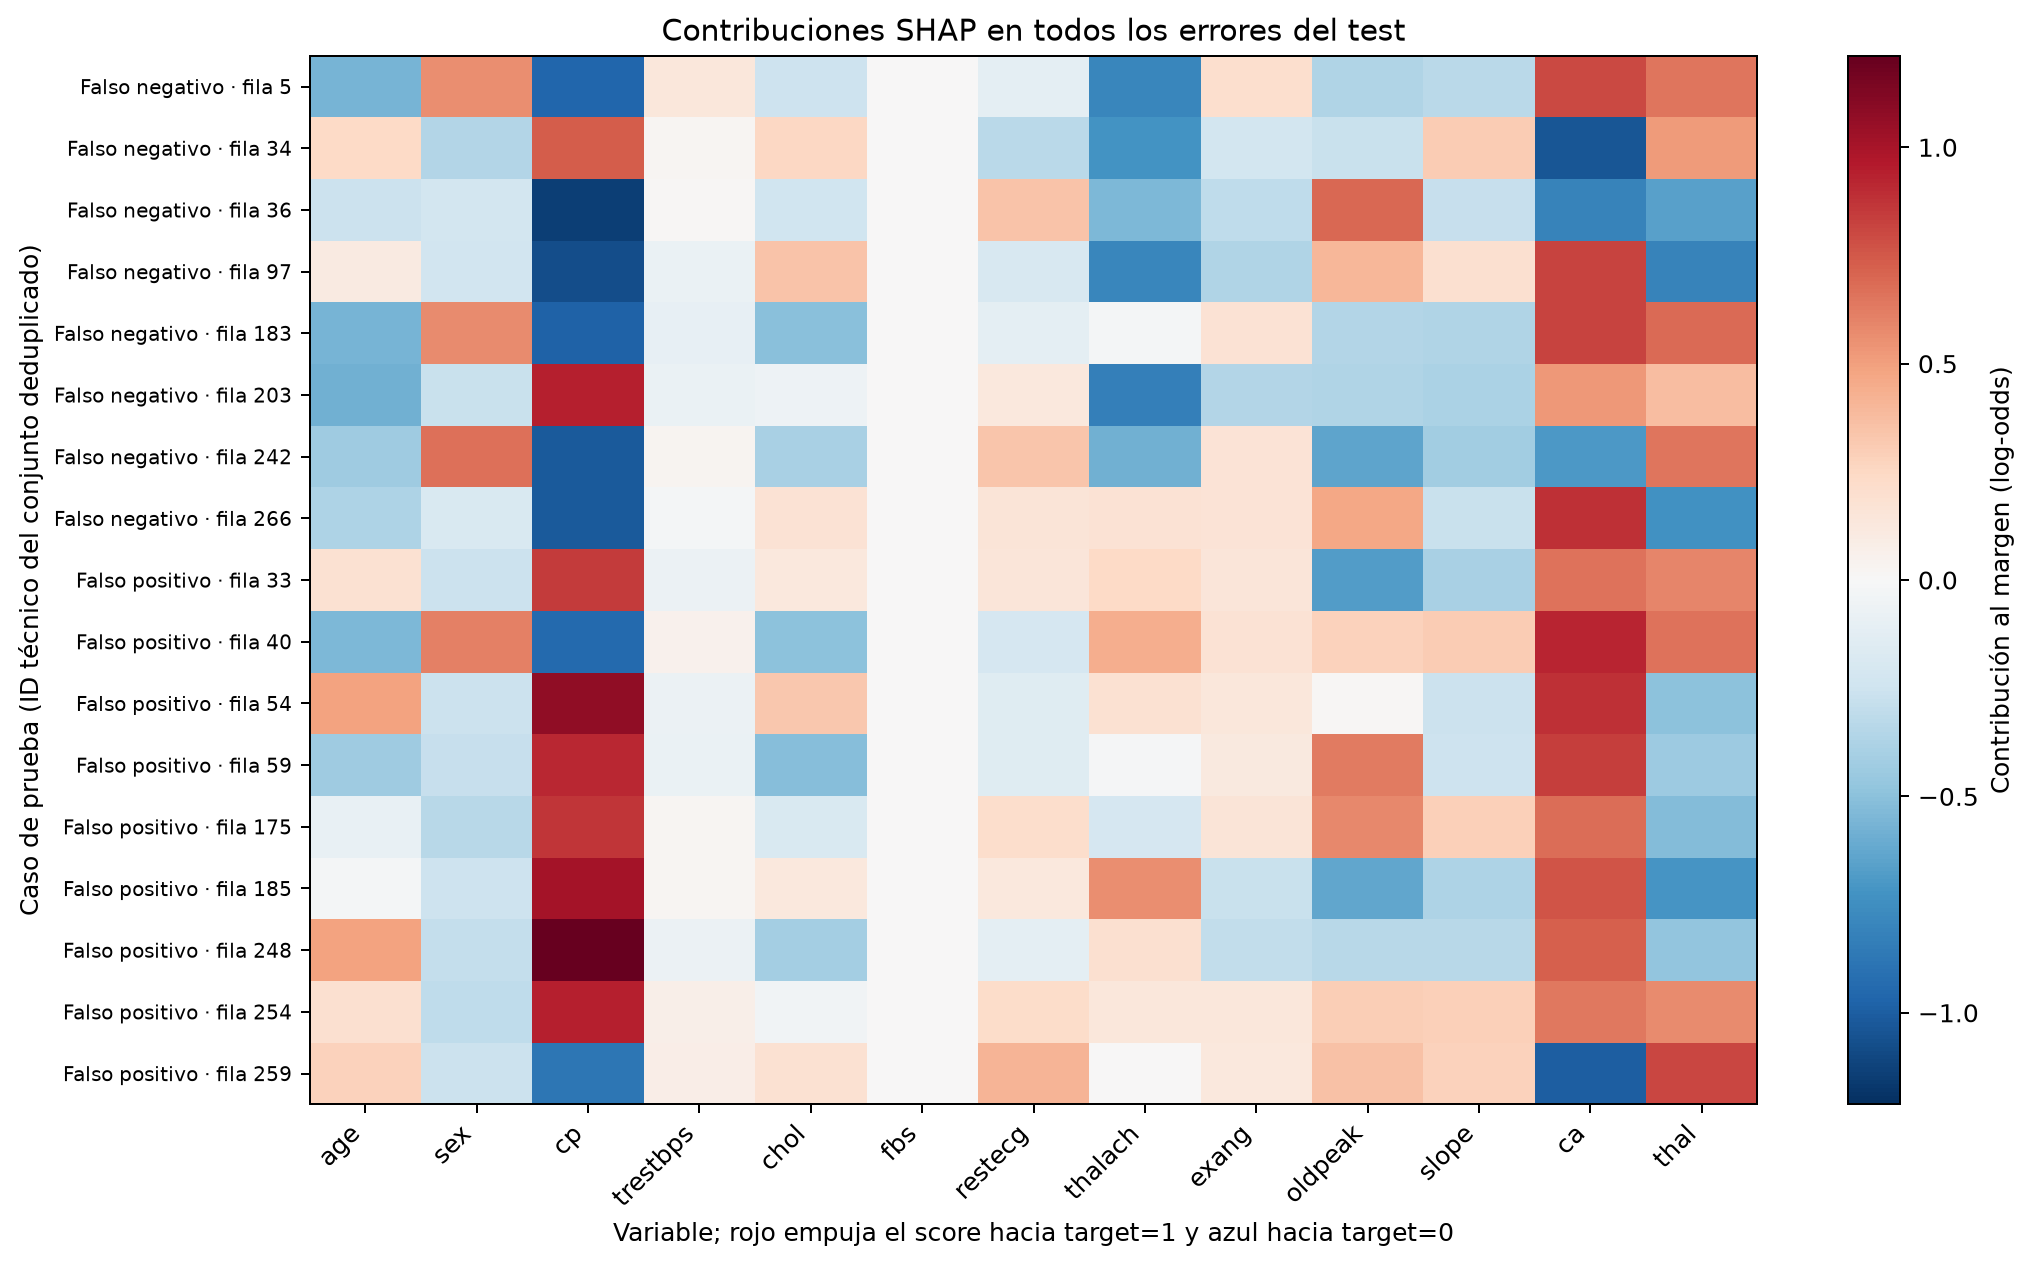

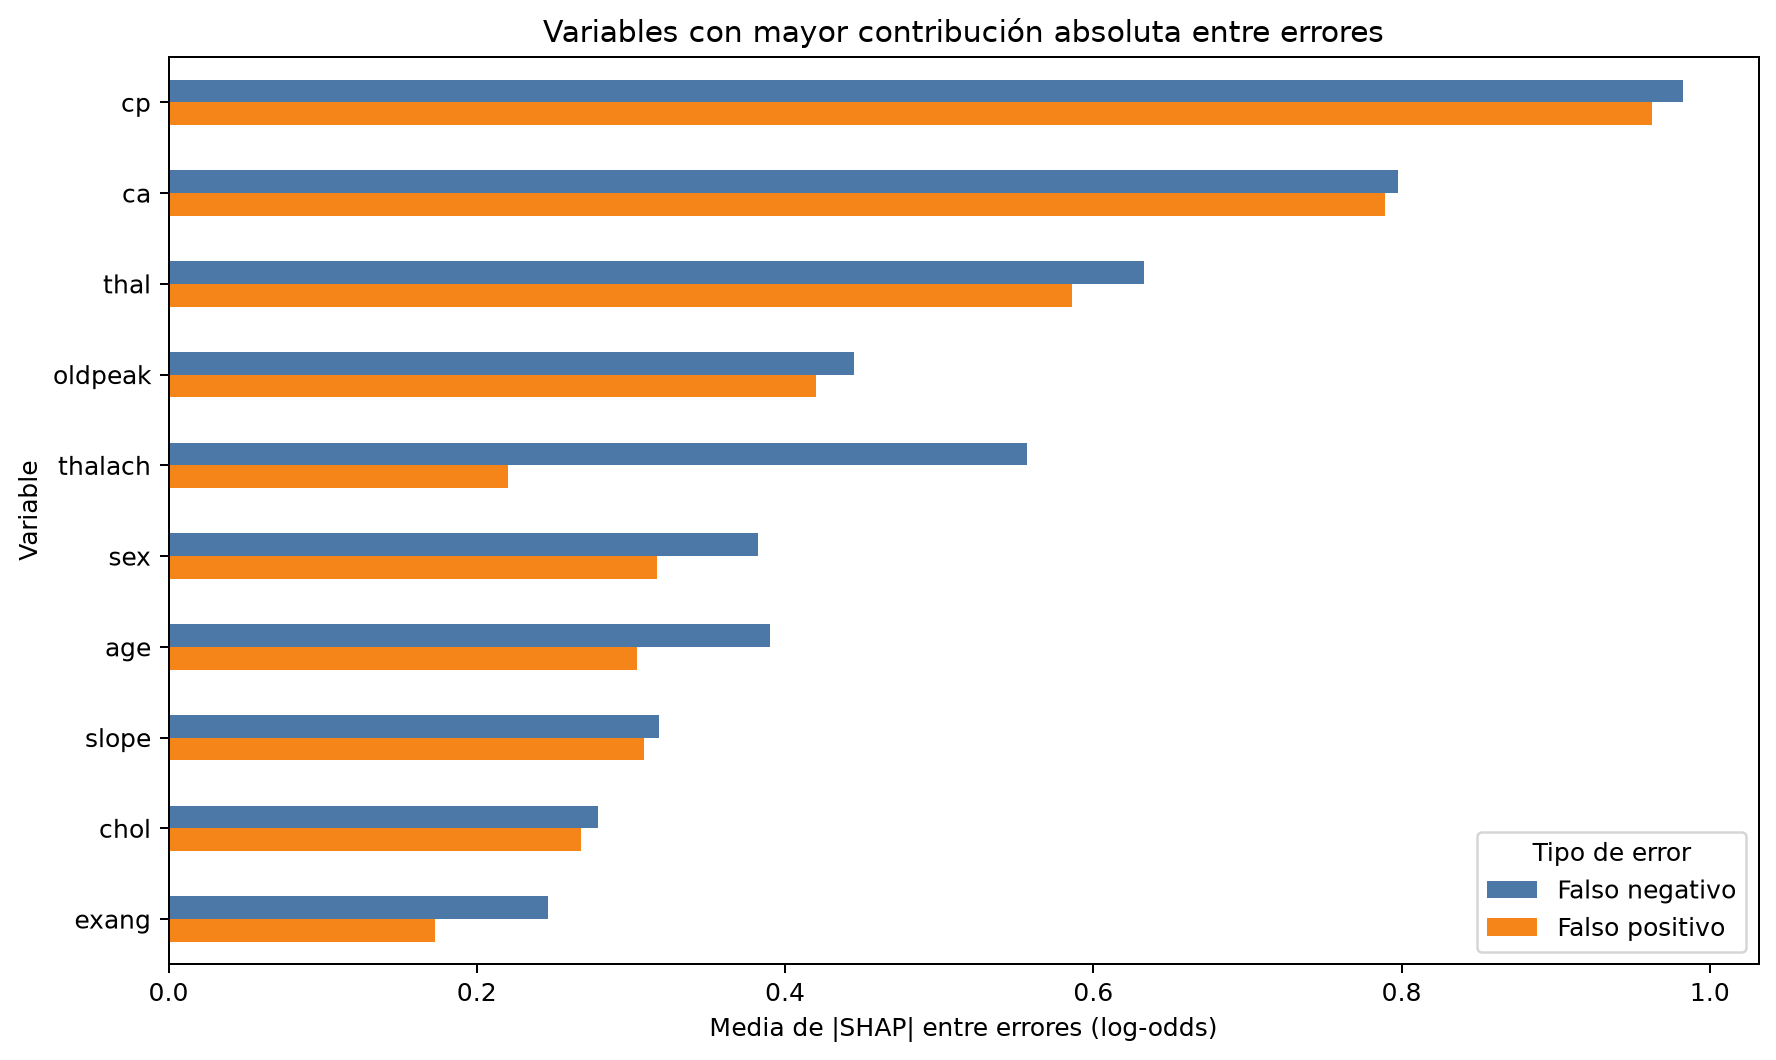

In [2]:
display(result['resumen_shap_errores'].groupby('error_type', sort=False).head(8))
display(Image(filename=str(ROOT / 'outputs/figures/shap_mapa_errores_test.png')))
display(Image(filename=str(ROOT / 'outputs/figures/shap_resumen_errores_test.png')))

## Métricas por subgrupo

Las filas `sex=0` y `sex=1` conservan los códigos del dataset, sin asumir una interpretación adicional. Las tasas dependen del número de positivos y negativos de cada grupo. La marca de soporte bajo se activa si n<10 o si una clase aporta menos de 5 casos. Los intervalos se muestran como referencia de incertidumbre y se solapan entre grupos; no debe concluirse que el modelo rinde de manera distinta ni que está libre de sesgo.

,dimension,grupo,n,target_0_n,target_1_n,tn,fp,fn,tp,accuracy,recall_target_1,recall_ci95_low,recall_ci95_high,specificity_target_0,specificity_ci95_low,specificity_ci95_high,small_support_flag
0,overall,Todos,76,35,41,26,9,8,33,0.776,0.805,0.660,0.898,0.743,0.579,0.858,False
1,sex,sex=0,22,6,16,5,1,3,13,0.818,0.812,0.570,0.934,0.833,0.436,0.970,False
2,sex,sex=1,54,29,25,21,8,5,20,0.759,0.800,0.609,0.911,0.724,0.543,0.853,False
3,age_group,60–69,25,17,8,14,3,4,4,0.720,0.500,0.215,0.785,0.824,0.590,0.938,False
4,age_group,50–59,29,11,18,8,3,4,14,0.759,0.778,0.548,0.910,0.727,0.434,0.903,False
5,age_group,40–49,16,4,12,2,2,0,12,0.875,1.000,0.758,1.000,0.500,0.150,0.850,True
6,age_group,<40,3,1,2,0,1,0,2,0.667,1.000,0.342,1.000,0.000,0.000,0.793,True
7,age_group,70+,3,2,1,2,0,0,1,1.000,1.000,0.207,1.000,1.000,0.342,1.000,True


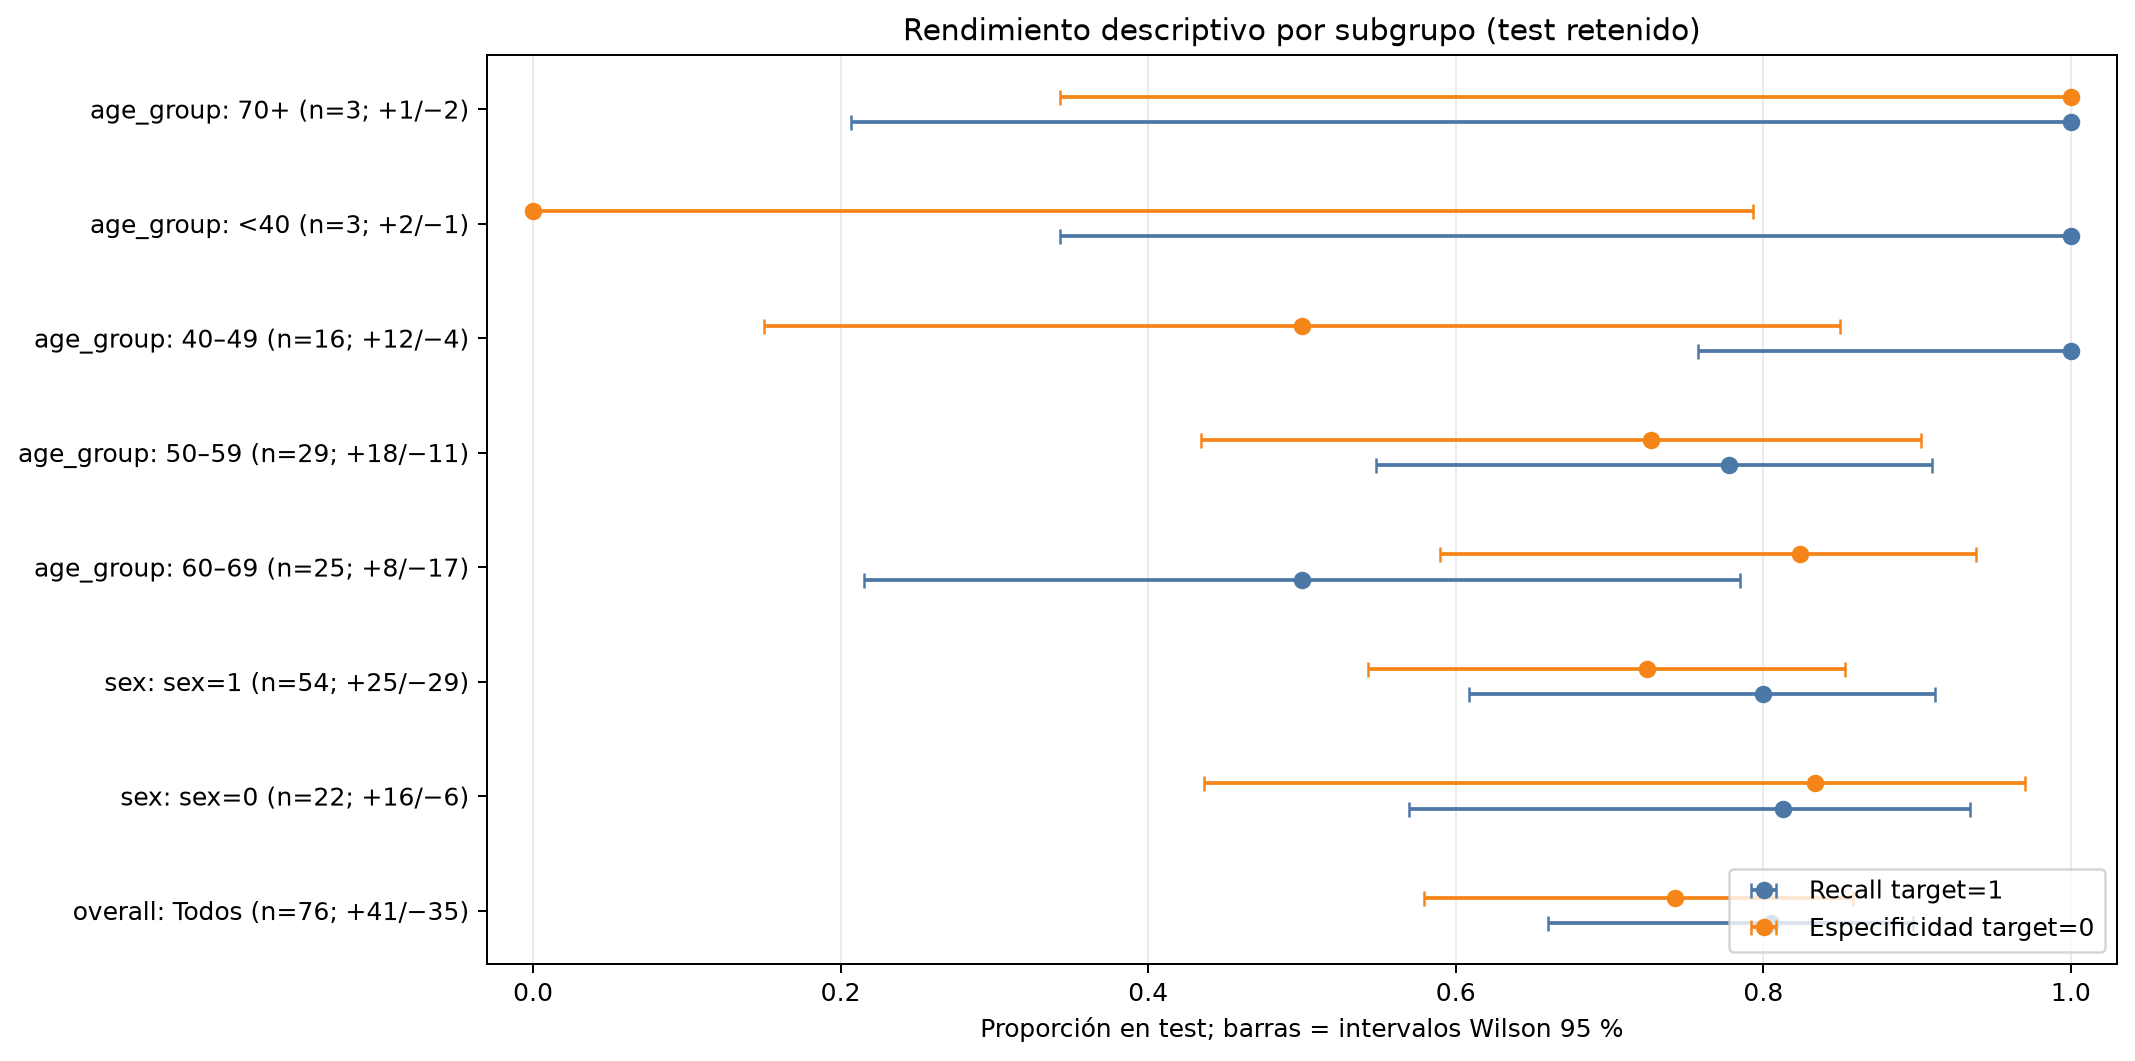

In [3]:
display(result['metricas_subgrupos'].round(3))
display(Image(filename=str(ROOT / 'outputs/figures/metricas_test_por_subgrupo.png')))

## Lectura y límites

En el test hay 8 falsos negativos y 9 falsos positivos. El conjunto completo deduplicado tiene 138 casos `target=0` y 164 `target=1`, por lo que no presenta un desbalance global marcado; eso no descarta sesgo de representación. Los códigos de sexo tienen tamaños distintos y la prueba es pequeña. Para conclusiones de equidad se necesitarían más observaciones, definiciones de subgrupo validadas, evaluación repetida y datos representativos. `target=1` se usa según la declaración del proveedor de Kaggle, no como etiqueta clínica independientemente validada.